# Gauss–Newton 方法

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

第07章已经量出了“旋钮影响表”。现在不妨这样做：先假装这张表在附近准确，算一组最合适的小调整；走过去后，重新量表，再算下一步。这就是 **Gauss–Newton（高斯—牛顿，简称 GN）方法**。

它像不断更新的小地图，不是拿一张平地图走遍整座山。主线只有三步：看当前误差、按局部直线规律求调整、到新位置再检查。

## 先看它会犯什么错

下面用一个只有两个参数的弯谷例子。我们知道真正最低点在 $(1,1)$，从 $(-1.2,1)$ 出发，先故意不限制步子。`unprotected full-step costs` 的第一项是起点分数，第二项是第一步后的分数。先猜：第一步会不会反而更糟？

`full GN` 表示直接走完局部建议，`GN + backtracking` 表示走前先试、太远就缩小。纵轴 `cost` 是总误差分数，越低越好；用了对数刻度，不要把图上的竖直距离当作普通差值。

这个例子的残差写作 $r=(10(x_2-x_1^2),1-x_1)^T$，叫 Rosenbrock 型残差。记住名字没有必要；它只是一个能让“大步冲过头”显形的小型测试地形。

## 想知道公式怎么来

把临时线性残差 $r+Jh$ 的平方和最小化：

$$h_{\rm GN}=\arg\min_h\|Jh+r\|^2,\qquad x_{\rm new}=x+h_{\rm GN}.$$

$h$ 是这轮改变量，不是最终参数。满列秩时它满足 $J^TJh=-J^Tr$，但代码直接用 `lstsq(J, -r)` 求解，避免先形成正规方程。

这相当于拿 $J^TJ$ 近似 Hessian，省掉第07章的 $\sum_i r_i\nabla^2r_i$。残差接近零且导数行为良好时，这种近似往往很好；若残差大、起点差、曲线弯得厉害，就可能失准。

unprotected full-step costs: [  12.1  1171.28    0.      0.      0.      0.      0.  ]
safeguarded estimate/status: [1. 1.] gradient


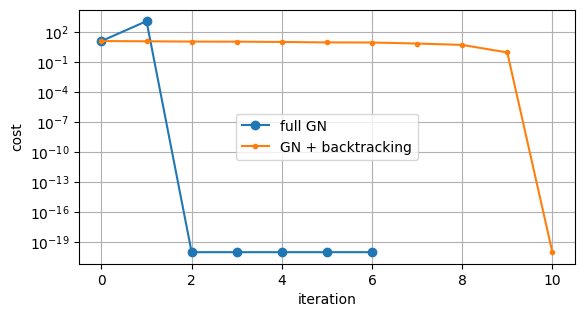

In [2]:
def rfun(x):
    return np.array([10*(x[1]-x[0]**2), 1-x[0]])
def jfun(x):
    return np.array([[-20*x[0], 10.], [-1., 0.]])
x = np.array([-1.2, 1.])
raw = [.5*rfun(x)@rfun(x)]
for _ in range(6):
    h = np.linalg.lstsq(jfun(x), -rfun(x), rcond=None)[0]
    x = x+h
    raw.append(.5*rfun(x)@rfun(x))
print('unprotected full-step costs:', np.array(raw))
assert raw[1] > raw[0]
safe = gauss_newton(rfun, jfun, [-1.2,1.])
print('safeguarded estimate/status:', safe.x, safe.status)
costs = [p['cost'] for p in safe.history]
plt.semilogy(np.maximum(raw, 1e-20), 'o-', label='full GN')
plt.semilogy(np.maximum(costs, 1e-20), '.-', label='GN + backtracking')
plt.xlabel('iteration'); plt.ylabel('cost'); plt.legend(); plt.show()
assert np.allclose(safe.x, [1,1], atol=1e-6)

## 给 GN 加一个“先试再走”的习惯

解出方向 $h$ 后，不马上照单全收，而是先算真实的 $F(x+\alpha h)$，必要时将 $\alpha$ 减半。这就是上章的回溯保护。它承认局部地图有用，却不一定管得了远处。

下面回到下降曲线。造数据时加了噪声，所以即使找到合理参数，总误差也不会必然归零。`ours` 是本书带保护的 GN，`SciPy` 是成熟工具作参照。两组参数和分数应接近；图上的拟合线应抓住总体下降趋势，而不是硬穿每个点。

这里的“真实目标非零”是说**原评分函数在拟合结果处不为零**，不是说我们采集了真实仪器数据。本章仍是合成数据实验。

ours: [2.50686 0.80254 0.4034 ] gradient cost: 0.013858140938455986
SciPy: [2.50686 0.80254 0.4034 ] cost: 0.013858140938455986


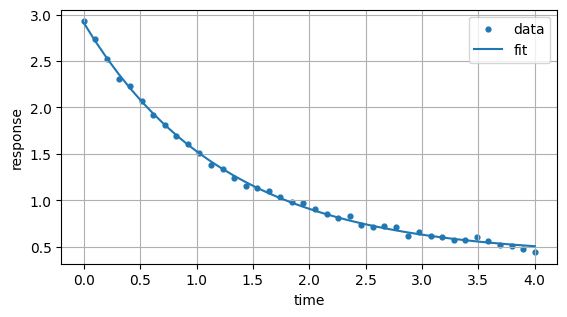

In [3]:
rng = np.random.default_rng(109)
t = np.linspace(0, 4, 40)
y = 2.5*np.exp(-.8*t)+.4+rng.normal(0,.035,len(t))
def residual(p):
    return p[0]*np.exp(-p[1]*t)+p[2]-y
def jac(p):
    e = np.exp(-p[1]*t)
    return np.column_stack([e,-p[0]*t*e,np.ones_like(t)])
ours = gauss_newton(residual, jac, [2., .5, .2], gtol=1e-8)
reference = least_squares(residual,[2., .5, .2],jac=jac,gtol=1e-12,ftol=1e-12,xtol=1e-12)
print('ours:', ours.x, ours.status, 'cost:', ours.cost)
print('SciPy:', reference.x, 'cost:', reference.cost)
assert np.allclose(ours.x, reference.x, atol=2e-5)
plt.scatter(t,y,s=12,label='data'); plt.plot(t,residual(ours.x)+y,label='fit')
plt.xlabel('time'); plt.ylabel('response'); plt.legend(); plt.show()

## 卡住时，先问地图和数据出了什么问题

如果两列雅可比几乎在做同一件事，叫“近秩亏”，局部计算可能建议一个很大的步；如果参数数值相差几千倍，同样的步长含义可能很不一致。先改善单位、缩放和测量条件，再考虑 LM 或信赖域限制步子。

**参数完全分不清时，保护走法也不能补出缺少的观测信息。**像只知道总价，不能因为换一种计算器就拆出每件单价。

## 自己试一下

在第一个实验中，把两处起点一起改成 `[-.5, .5]`，比较有无回溯的曲线。原来的 `assert raw[1] > raw[0]` 只针对原起点；换起点探索时可以先注释它，别把“必须第一步变差”当成算法定律。

问题一：如果残差本来就是 $Ax-y$，GN 要走几次？

解答：精确计算、满秩且完整走步时，一次就到最小二乘解。因为临时地图恰好就是完整问题。

问题二：读数个数比参数少，也能返回一步吗？

解答：可以选一个最小范数步，但有些参数方向缺少约束，不能因此宣称答案唯一。

问题三：未经保护最后也到了最低点，为什么还要保护？

解答：中途的大幅变差在其他模型里可能产生溢出、负的物理量或跑到另一个局部最低点。本次最后成功，没有证明这种走法处处可靠。